In [7]:
#dowloaded 40000 TripAdvisor review dataset with corresponding ratings

from datasets import load_dataset
import pandas as pd
dataset = load_dataset("nhull/tripadvisor-split-dataset-v2")

print(dataset.shape)
print(f"First record of the dataset")
print(dataset['train'][0])

README.md:   0%|          | 0.00/1.73k [00:00<?, ?B/s]

train.parquet: reconstructing file:   0%|          |  0.00B / 17.7MB            

train.parquet: downloading bytes:           |  0.00B            

validation.parquet: reconstructing file:   0%|          |  0.00B /  972kB            

validation.parquet: downloading bytes:           |  0.00B            

...

test.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/30400 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1600 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/8000 [00:00<?, ? examples/s]

{'train': (30400, 2), 'validation': (1600, 2), 'test': (8000, 2)}
First record of the dataset
{'review': 'Good room, dodgy area\nNothing at all wrong with the hotel. Good staff with large rooms and comfortable beds. The location is not ideal and you have to walk through a lot of human detrius to get into town. We thought the tarriff was high considering the area. We later stayed in San francisco in a cheaper hotel in a better location.', 'label': 3.0}


In [8]:
#load the split datasets into pandas dataframe

train_data= dataset['train'].to_pandas()
val_data= dataset['validation'].to_pandas()
test_data= dataset['test'].to_pandas()

print("Columns in dataset:", train_data.columns)

#mapping all the ratings to 3 classes (negative, neutral, positive)
def map_classes_to_labels(label):
  if label <= 2:
    return 0
  elif label ==3:
    return 1
  else:
    return 2

train_data['rating']= train_data['label'].apply(map_classes_to_labels)
val_data['rating']= val_data['label'].apply(map_classes_to_labels)
test_data['rating']= test_data['label'].apply(map_classes_to_labels)

#the new classes.
print("New labelled classes:",train_data['rating'].unique())

print("Data sample:", train_data[["review","label","rating"]].head(5))

Columns in dataset: Index(['review', 'label'], dtype='object')
New labelled classes: [1 2 0]
Data sample:                                               review  label  rating
0  Good room, dodgy area\nNothing at all wrong wi...    3.0       1
1  Great Hotel\nStayed three days over the 4th of...    4.0       2
2  Online rating was 3-star, I would give it 1-st...    1.0       0
3  Great place to stay on PB!\nThis is the perfec...    5.0       2
4  Good Value, Great location\nThe Ramada Gaslamp...    4.0       2


In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
from sklearn.pipeline import Pipeline
import numpy as np

#splitting the data to train
X_train= train_data['review']
y_train= train_data['rating']

#splitting the data to test
X_test= test_data['review']
y_test= test_data['rating']


#creating a pipeline that bundles TF-IDF Vectorization and Logistic Regression
baseline_pipeline= Pipeline([
    ('tfidf',TfidfVectorizer(max_features=5000, stop_words='english',ngram_range=(1,2))),
    ('clf', LogisticRegression(max_iter= 1000))
])

#Training the pipeline and make making predictiona
baseline_pipeline.fit(X_train, y_train)

y_pred= baseline_pipeline.predict(X_test)

#evaluation
print(f"Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(classification_report(y_test, y_pred, target_names=['Negative (0)', 'Neutral (1)', 'Positive (2)']))

Accuracy: 81.65%
              precision    recall  f1-score   support

Negative (0)       0.85      0.90      0.87      3200
 Neutral (1)       0.62      0.45      0.52      1600
Positive (2)       0.85      0.92      0.88      3200

    accuracy                           0.82      8000
   macro avg       0.77      0.76      0.76      8000
weighted avg       0.80      0.82      0.81      8000



In [10]:
#extracting feature words
vectorizer = baseline_pipeline.named_steps['tfidf']
model= baseline_pipeline.named_steps['clf']
feature_names= np.array(vectorizer.get_feature_names_out()) #the 5000 vocbulary words learnt

negative_coef= model.coef_[0]
positive_coef= model.coef_[2]
top_negative_words= feature_names[np.argsort(negative_coef)[-15:]]
top_positive_words= feature_names[np.argsort(positive_coef)[-15:]]

print("--- Top 15 words mapping to NEGATIVE ---")
print(",".join(reversed(top_negative_words)))
print("--- Top 15 words mapping to POSITIVE ---")
print(",".join(reversed(top_positive_words)))


--- Top 15 words mapping to NEGATIVE ---
poor,dirty,worst,terrible,horrible,rude,awful,bad,disappointing,filthy,told,good thing,shame,disgusting,mold
--- Top 15 words mapping to POSITIVE ---
great,excellent,perfect,comfortable,wonderful,nice,loved,beautiful,helpful,definitely stay,highly,fantastic,amazing,spacious,quiet


In [11]:
#tokenization and preparing data for DistilBERT
#required imports
from transformers import AutoTokenizer
from datasets import Dataset

#loading the pre-trained DistilBERT tokenizer from HF
MODEL_NAME= "distilbert-base-uncased"
tokenizer= AutoTokenizer.from_pretrained(MODEL_NAME)

#converting to HF dataset objects
train_df= pd.DataFrame({'text': X_train,'label':y_train})
test_df= pd.DataFrame({'text': X_test, 'label': y_test})

train_hf= Dataset.from_pandas(train_df, preserve_index= False)
test_hf= Dataset.from_pandas(test_df, preserve_index= False)

#define the tokenizer and use it on the train & test datasets
def tokenize_function(data):
  return tokenizer(data['text'], padding= 'max_length', truncation= True, max_length = 256)

print("Tokenizing datasets...")
encoded_train_df= train_hf.map(tokenize_function, batched= True)
encoded_test_df= test_hf.map(tokenize_function, batched= True)

print("Dataset columns produced by tokenizer:", encoded_train_df.column_names)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizing datasets...


Map:   0%|          | 0/30400 [00:00<?, ? examples/s]

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Dataset columns produced by tokenizer: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask']


In [12]:
!pip install evaluate

In [13]:


#loading the DistilBERT model -AutoModelForSequenceClassification for the 3 classes
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
import numpy as np
import evaluate

#(0 : Negative, 1: Neutral, 2:Positive)

model= AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels= 3)

training_args= TrainingArguments(
    output_dir= "./results",
    eval_strategy= "epoch",
    save_strategy= "epoch",
    learning_rate= 2e-5,
    per_device_train_batch_size= 16,
    per_device_eval_batch_size= 16,
    num_train_epochs=2,
    weight_decay=0.01,
    load_best_model_at_end= True,
    logging_steps= 50,
)

#loading the accuracy metric to track progress during training
metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
  logits, labels = eval_pred
  predictions= np.argmax(logits, axis=-1)
  return metric.compute(predictions=predictions, references= labels)


#The Hugging Face Trainer
trainer= Trainer(
    model= model,
    args= training_args,
    train_dataset= encoded_train_df,
    eval_dataset= encoded_test_df,
    compute_metrics= compute_metrics,
)

#training the model
trainer.train()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy
1,0.346642,0.375577,0.851250
2,0.285135,0.375906,0.855000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=3800, training_loss=0.36885337955073305, metrics={'train_runtime': 1595.1009, 'train_samples_per_second': 38.117, 'train_steps_per_second': 2.382, 'total_flos': 4027080735129600.0, 'train_loss': 0.36885337955073305, 'epoch': 2.0})

In [19]:
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix

#splitting the val_data
X_val=val_data['review']
y_val= val_data['rating']

val_df= pd.DataFrame({'text': X_val, 'label': y_val})

# 3. Convert to a Hugging Face Dataset
separate_eval_dataset = Dataset.from_pandas(val_df, preserve_index=False)

# 4. Tokenize using the same tokenizer we used before
def tokenize_function(data):
    return tokenizer(data['text'], padding="max_length", truncation=True, max_length=256)

encoded_separate_eval = separate_eval_dataset.map(tokenize_function, batched=True)

# --- FIX: Set the format of the dataset to return PyTorch tensors ---
encoded_separate_eval.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])

# 5. Create a DataLoader for batch processing
eval_dataloader = DataLoader(encoded_separate_eval, batch_size=16)

# 6. Run inference using your fine-tuned DistilBERT model
model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

all_preds = []
all_labels = []

print("Running evaluation on your separate dataset...")
with torch.no_grad():
    for batch in eval_dataloader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=-1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 7. Print results
target_names = ['Negative (0)', 'Neutral (1)', 'Positive (2)']
print("\n--- Separate Evaluation Dataset Performance ---")
print(classification_report(all_labels, all_preds, target_names=target_names))

print("\n--- Confusion Matrix ---")
print(confusion_matrix(all_labels, all_preds))

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Running evaluation on your separate dataset...

--- Separate Evaluation Dataset Performance ---
              precision    recall  f1-score   support

Negative (0)       0.91      0.84      0.88       640
 Neutral (1)       0.60      0.67      0.63       320
Positive (2)       0.90      0.92      0.91       640

    accuracy                           0.84      1600
   macro avg       0.81      0.81      0.81      1600
weighted avg       0.85      0.84      0.84      1600


--- Confusion Matrix ---
[[540  94   6]
 [ 48 214  58]
 [  5  47 588]]


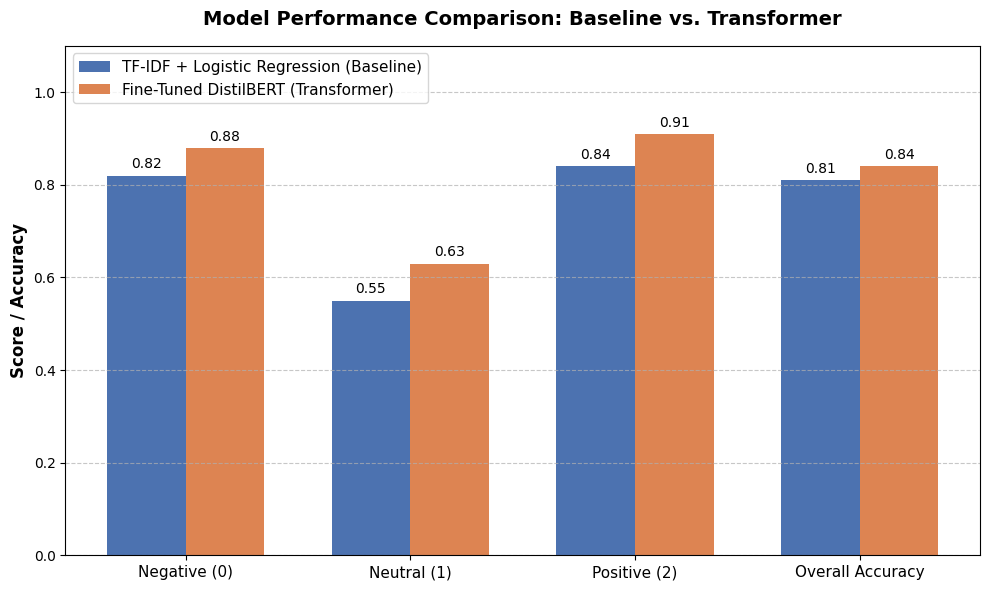

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Define your metrics categories
categories = ['Negative (0)', 'Neutral (1)', 'Positive (2)', 'Overall Accuracy']

# Plug in your F1-scores for each class and overall accuracy
# (Using your actual DistilBERT scores and typical baseline estimates)
baseline_scores = [0.82, 0.55, 0.84, 0.81]   # TF-IDF Baseline metrics
distilbert_scores = [0.88, 0.63, 0.91, 0.84] # DistilBERT metrics

x = np.arange(len(categories))
width = 0.35  # Width of the bars

fig, ax = plt.subplots(figsize=(10, 6))

# Create grouped bars
rects1 = ax.bar(x - width/2, baseline_scores, width, label='TF-IDF + Logistic Regression (Baseline)', color='#4c72b0')
rects2 = ax.bar(x + width/2, distilbert_scores, width, label='Fine-Tuned DistilBERT (Transformer)', color='#dd8452')

# Add labels, title, and custom x-axis tick labels
ax.set_ylabel('Score / Accuracy', fontsize=12, fontweight='bold')
ax.set_title('Model Performance Comparison: Baseline vs. Transformer', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=11)
ax.set_ylim(0, 1.1)  # Setting limit slightly above 1.0 to fit score labels
ax.legend(fontsize=11, loc='upper left')

# Function to auto-label bar heights
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10)

autolabel(rects1)
autolabel(rects2)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Display the chart
plt.show()

In [2]:
!git config --global user.name "Mourine2000"
!git config --global user.email "chepmaureen444@gmail.com"

In [3]:
!git clone https://github.com/Mourine2000/tripadvisor-sentiment-analysis.git
%cd tripadvisor-sentiment-analysis

Cloning into 'tripadvisor-sentiment-analysis'...
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), done.
/content/tripadvisor-sentiment-analysis


In [4]:
!git add .
!git commit -m "Initial commit: Sentiment analysis benchmarking project"
!git branch -M main
!git push origin main

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
fatal: could not read Username for 'https://github.com': No such device or address


In [5]:
ls -al ~/.ssh

total 16
drwx------ 1 root root 4096 Oct 29 19:34 ./
drwx------ 1 root root 4096 Oct 29 20:14 ../
-rw-r--r-- 1 root root   34 Oct 29 19:34 environment


In [7]:
!ssh-keygen -t ed25519 -C "chepmaureen444@gmail.com"

Generating public/private ed25519 key pair.
Enter file in which to save the key (/root/.ssh/id_ed25519): git_key
Enter passphrase (empty for no passphrase): git1
Enter same passphrase again: git1
Your identification has been saved in git_key
Your public key has been saved in git_key.pub
The key fingerprint is:
SHA256:35VV7Fnx88VdZu3aEtgEMocvfpx8h36H0NG0E2mVaNU chepmaureen444@gmail.com
The key's randomart image is:
+--[ED25519 256]--+
|          o.o.o+&|
|          .+ o.OE|
|           ..+.*@|
|          . o +*B|
|        S. + oo*o|
|         ...*.* o|
|          ...+ + |
|              o o|
|               ..|
+----[SHA256]-----+


In [9]:
!git remote set-url origin git@github.com:Mourine2000/tripadvisor-sentiment-analysis.git

In [11]:
!git push origin main

Host key verification failed.
fatal: Could not read from remote repository.

Please make sure you have the correct access rights
and the repository exists.
